In [4]:
from bill_classifier import classify_bill
from img_segment import PerspectiveTransform
import pytesseract
import cv2
import numpy as np
import matplotlib.pyplot as plt
import json
import re

pytesseract.pytesseract.tesseract_cmd = 'C:/Program Files/Tesseract-OCR/tesseract.exe'

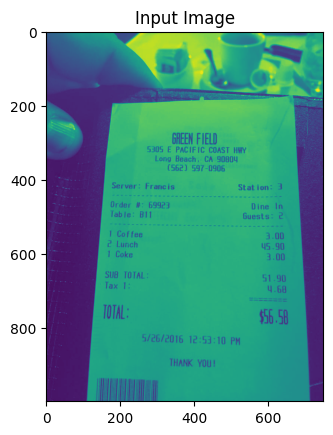

In [7]:
#Reading and collecting the image receipt input
file_path = 'receipts/1000-receipt.jpg'
img = cv2.imread(file_path, 0)
plt.title('Input Image')
plt.imshow(img)
plt.show()

In [8]:
#Normalizing the image
img_mean = np.mean(img) #Image mean 
img_std = np.std(img) #Image standard deviation
z_score = np.uint8(img - img_mean / img_std) #Z-Score of the image

In [9]:
result = pytesseract.image_to_string(z_score, config="--psm 4")
print(result)

GREEN FIELD
5305 E PACIFIC COAST HWY
Long Beach, CA 90804
(562) 597-0906
Server: Francis Station: 4

Order #: 69923 Dine In
Table: B11 Guests: 2

1 Coffee ae 3.00

2 Lunch 45.90

1 Coke 3.00

SUB TOTAL: 51.90

Tax 1: 4.68

TOTAL: $96.48
5/26/2016 12:53:10 PM

AH

THANK YOU!




In [10]:
#Formatting the string data to JSON
def format_result(data):
    json_data = {
        "shop_name": None,
        "location": None,
        "sub_total": None,
        "tax": None,
        "total": None,
        "date": None,
    }

    lst = data.splitlines()
    if "!@#$%^&*()-_+=|\/;:'<>,." in lst[0]:
            lst.pop(0)
    date_patterns = r"\b\d{1}/\d{2}/\d{4}\b"
    for ind, val in enumerate(lst):
        if ind == 0:
            json_data['shop_name'] = lst[ind]
        elif ind == 1 or ind == 2:
            if ind == 1:
                json_data['location'] = (lst[ind] + ",")
            else:
                json_data['location'] += (" " + lst[ind])
        elif "sub total" in val.lower():
            json_data['sub_total'] = re.findall(r"\d+\.\d+|\d+", val)
        elif "tax" in val.lower():
            json_data['tax'] = re.findall(r"\d+\.\d+", val)
        elif "total" in val.lower():
            json_data['total'] = re.findall(r"\d+\.\d+|\d+", val)
        date_value = re.findall(date_patterns, val)
        if date_value:
            json_data['date'] = date_value
    return json.dumps(json_data, indent=4)

<>:13: SyntaxWarning: invalid escape sequence '\/'
<>:13: SyntaxWarning: invalid escape sequence '\/'
C:\Users\balat\AppData\Local\Temp\ipykernel_15916\1882830470.py:13: SyntaxWarning: invalid escape sequence '\/'
  if "!@#$%^&*()-_+=|\/;:'<>,." in lst[0]:


In [11]:
json_results = json.loads(format_result(result))
print(json_results)

{'shop_name': 'GREEN FIELD', 'location': '5305 E PACIFIC COAST HWY, Long Beach, CA 90804', 'sub_total': ['51.90'], 'tax': ['4.68'], 'total': ['96.48'], 'date': ['5/26/2016']}


In [12]:
categories = {
    "Food": {
        "file_path": None,
        "total": None,
        "tax": None
    },
    "Travel": {
        "bill_path": None,
        "total": None,
        "tax": None
    },
    "Accomodation": {
        "bill_path": None,
        "total": None,
        "tax": None
    }
}

def categorize_bill(result, json_data):
    global category
    category = classify_bill(result)
    categories[category]["total"] = json_data["total"]
    categories[category]["file_path"] = file_path
    categories[category]["tax"] = json_data["tax"]

In [13]:
categorize_bill(result, json_results)
print(categories[category])
print(f"Category: {category}")

{'file_path': 'receipts/1000-receipt.jpg', 'total': ['96.48'], 'tax': ['4.68']}
Category: Food
